In [1]:
import pandas as pd
import numpy as np

# Loading Data

In [2]:
df_metadata = pd.read_csv("data/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512/Metadata_Country_API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512.csv", index_col=["Country Code"])

df_raw = pd.read_csv(f"data/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512.csv", index_col=["Country Code"])

# Checking Proper Region

In [3]:
df_metadata.head()

,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
Country Code,,,,,
ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
AFG,Middle East & North Africa,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


In [4]:
df_metadata["Region"].unique()

array(['Latin America & Caribbean', nan, 'Middle East & North Africa',
       'Sub-Saharan Africa', 'Europe & Central Asia',
       'East Asia & Pacific', 'South Asia', 'North America'], dtype=object)

In [5]:
countrycodes = df_metadata[df_metadata["Region"].notna()].index

countrycodes

Index(['ABW', 'AFG', 'AGO', 'ALB', 'AND', 'ARE', 'ARG', 'ARM', 'ASM', 'ATG',
       ...
       'VGB', 'VIR', 'VNM', 'VUT', 'WSM', 'XKX', 'YEM', 'ZAF', 'ZMB', 'ZWE'],
      dtype='object', name='Country Code', length=217)

# Extracting Data

In [6]:
df_selcountries = df_raw.loc[countrycodes].drop(columns=["Indicator Name", "Indicator Code", "Unnamed: 70"])

selcountries = df_selcountries["2025"].nlargest(len(df_selcountries)).index

selcountries

Index(['USA', 'CHN', 'DEU', 'JPN', 'GBR', 'IND', 'FRA', 'RUS', 'ITA', 'CAN',
       ...
       'NCL', 'PRK', 'PYF', 'SMR', 'SSD', 'SYR', 'TCA', 'VGB', 'VIR', 'YEM'],
      dtype='object', name='Country Code', length=217)

In [7]:
df_final = df_selcountries.loc[selcountries].drop(columns=[f"{year}" for year in range(1960, 1990)]).dropna(axis=0)\
    .drop(columns = "Country Name").T.sort_index()

df_final.index = df_final.index.astype(int)

df_final

Country Code,USA,CHN,DEU,JPN,GBR,IND,FRA,RUS,ITA,CAN,...,KNA,STP,DMA,TON,FSM,KIR,PLW,MHL,NRU,TUV
1990,5.963144e+12,3.615602e+11,1.778162e+12,3.252994e+12,1.093169e+12,3.209790e+11,1.257649e+12,5.170144e+11,1.183945e+12,5.960756e+11,...,2.172593e+08,1.192979e+08,2.014296e+08,1.135638e+08,147200000.0,3.653429e+07,9.770230e+07,78476000.0,5.557238e+07,9.542901e+06
1991,6.158129e+12,3.845105e+11,1.875793e+12,3.724888e+12,1.142797e+12,2.701053e+11,1.258962e+12,5.179630e+11,1.249092e+12,6.125277e+11,...,2.205407e+08,1.074841e+08,2.197630e+08,1.322011e+08,166200000.0,4.124779e+07,1.065553e+08,82507000.0,5.253379e+07,1.012731e+07
1992,6.520327e+12,4.285024e+11,2.141378e+12,4.064530e+12,1.179660e+12,2.882081e+11,1.389663e+12,4.602906e+11,1.323204e+12,5.943874e+11,...,2.421370e+08,9.486178e+07,2.340593e+08,1.370663e+08,178100000.0,6.149137e+07,1.047713e+08,91063000.0,5.113312e+07,1.053503e+07
1993,6.858559e+12,4.465573e+11,2.078954e+12,4.632481e+12,1.061389e+12,2.792956e+11,1.314383e+12,4.350837e+11,1.067413e+12,5.790536e+11,...,2.637556e+08,1.257422e+08,2.455259e+08,1.384899e+08,198400000.0,5.895360e+07,9.645570e+07,99461000.0,4.354209e+07,1.041440e+07
1994,7.287236e+12,5.669295e+11,2.215283e+12,5.104063e+12,1.140490e+12,3.272748e+11,1.385823e+12,3.950773e+11,1.101750e+12,5.799443e+11,...,2.951593e+08,1.313384e+08,2.643741e+08,1.959910e+08,202500000.0,6.705533e+07,1.061385e+08,108071000.0,3.974251e+07,1.177261e+07
1995,7.639749e+12,7.381909e+11,2.593053e+12,5.639650e+12,1.349094e+12,3.602819e+11,1.595219e+12,3.955372e+11,1.177369e+12,6.059611e+11,...,3.134852e+08,1.036952e+08,2.745222e+08,2.088717e+08,219930000.0,6.859639e+07,1.210185e+08,120230000.0,3.996971e+07,1.192261e+07
1996,8.073122e+12,8.685239e+11,2.506577e+12,5.021442e+12,1.425287e+12,3.928969e+11,1.598889e+12,3.917249e+11,1.314777e+12,6.306080e+11,...,3.339444e+08,1.351882e+08,2.922852e+08,2.221006e+08,216546000.0,8.145685e+07,1.374946e+08,110858000.0,3.745880e+07,1.333860e+07
1997,8.577552e+12,9.677536e+11,2.218791e+12,4.579781e+12,1.569317e+12,4.158676e+11,1.449392e+12,4.049290e+11,1.244988e+12,6.549877e+11,...,3.746413e+08,9.192027e+07,3.029889e+08,2.149915e+08,204397200.0,8.020581e+07,1.438608e+08,109884700.0,3.733151e+07,1.373421e+07
1998,9.062817e+12,1.037134e+12,2.247760e+12,4.150359e+12,1.660821e+12,4.213513e+11,1.496906e+12,2.709555e+11,1.272730e+12,6.339993e+11,...,3.832573e+08,7.228540e+07,3.224111e+08,1.915049e+08,216520600.0,7.490571e+07,1.490796e+08,112070100.0,2.966445e+07,1.379515e+07
1999,9.631172e+12,1.103843e+12,2.213873e+12,4.688983e+12,1.693459e+12,4.588211e+11,1.486916e+12,1.959071e+11,1.255005e+12,6.784142e+11,...,4.065955e+08,7.730221e+07,3.317593e+08,1.992087e+08,217198900.0,7.732398e+07,1.442065e+08,113352100.0,2.732861e+07,1.480050e+07


# Small plotting

In [8]:
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
import seaborn as sns

In [9]:
def configure_axis(ax: Axes, title: str|None = None, xlab: str|None = "year", ylab: str|None = "GDP [USD]", legend: bool = False, xticks: list|np.ndarray|None=None):
    ax.grid(True, which="major", lw = 0.5, color = "black", ls = "--")
    ax.axhline(0, color = "black", lw = 0.75)
    ax.axvline(1990, color = "black", lw = 0.75)

    ax.tick_params("x", rotation=45)

    if xticks is not None:
        ax.set_xticks(xticks)
    
    if legend:
        ax.legend()
    if title is not None:
        ax.set_title(title)
    if xlab is not None:
        ax.set_xlabel(xlab)
    if ylab is not None:
        ax.set_ylabel(ylab)

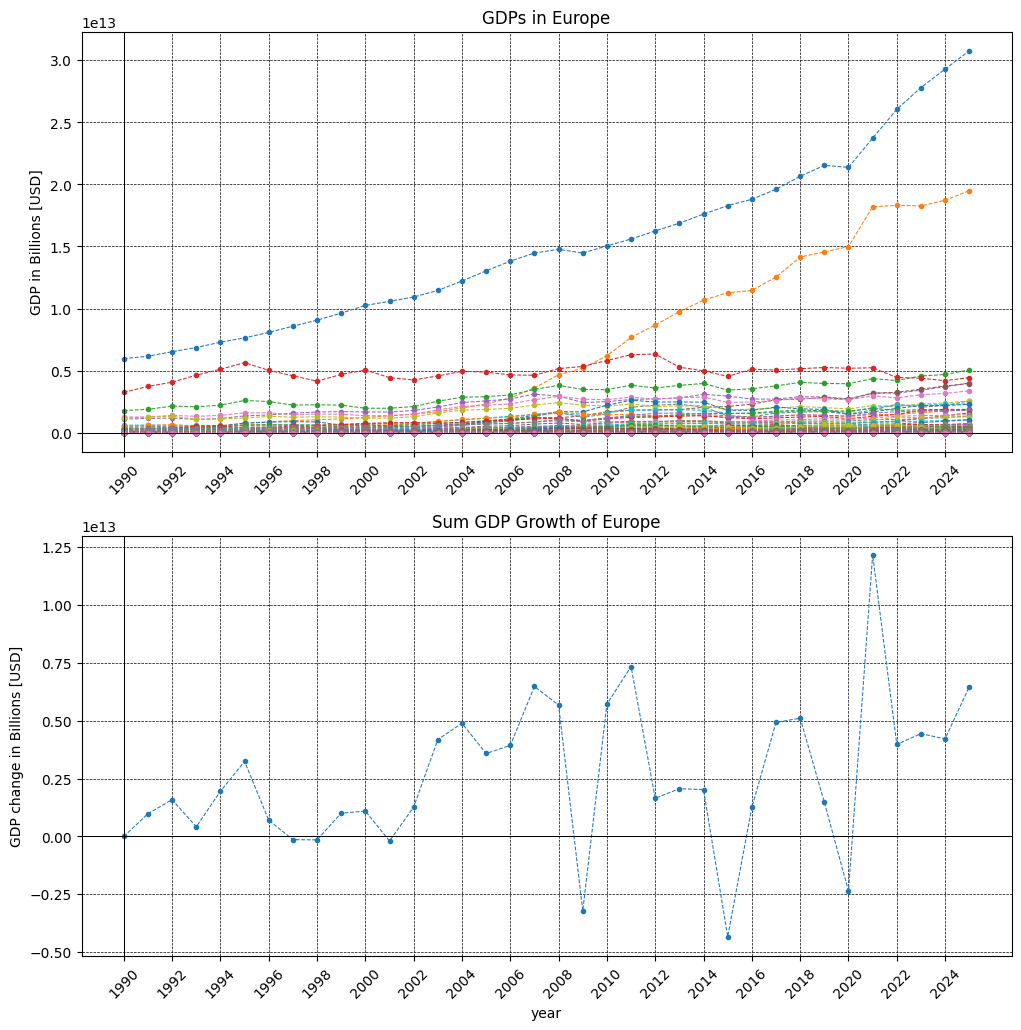

In [10]:
fig, (axgdp, axgrow) = plt.subplots(2, 1, figsize = (12, 6*2))

for country in df_final.columns:
    axgdp.plot(df_final[country], ls = "--", lw = 0.75, marker = ".", label = country)


axgrow.plot(df_final.diff().sum(axis=1), ls = "--", lw = 0.75, marker = ".", label = "growth")


configure_axis(axgdp, title="GDPs in Europe", ylab="GDP in Billions [USD]", xlab=None, xticks=df_final.index[::2].tolist())
configure_axis(axgrow, title = "Sum GDP Growth of Europe", ylab="GDP change in Billions [USD]", xticks=df_final.index[::2].tolist())

In [11]:
df_final.to_csv(f"data/stats/europe-gdp-1990-2025-billion-usd.csv")

# Extracting Tags

In [12]:
df_selcountries.loc[df_final.columns]["Country Name"].to_csv("scenarios/top-100-states-1995-2025/tags.csv")